# Simulations: Should sample size be contractible?

Gaussian model $X_i \overset{iid}{\sim} \mathcal{N}(\theta, 1)$, evidence $Z_n = \sqrt{n}\,\bar X_n \sim \mathcal{N}(\theta\sqrt n, 1)$, linear cost $c(n) = c_0 + c_1 n$, max license value $R$.

By the Neyman–Pearson / Karlin–Rubin characterization, the optimal incentive-aligned contract of each type is an **all-or-nothing threshold rule on $Z_n$**, so the two contracts differ *only in their testing level*:

- **Contract A** (sample size not contractible): null deterrence must hold at the null's cheapest deviation, so the level is
  $\alpha_A = \min\{1,\; c_{\min}/R\}$ with $c_{\min} = \min_{n \in \mathcal N} c(n)$, *uniform in $n$*.
- **Contract B** (sample size contractible): the option at $n$ needs only $R\,\alpha \le c(n)$, so
  $\alpha_B(n) = \min\{1,\; c(n)/R\}$.

Passing probability of type $\theta$ at sample size $n$ and level $\alpha$:
$$ p(n, \theta; \alpha) = 1 - \Phi\big(z_{1-\alpha} - \theta\sqrt{n}\big), $$
which is exact (no Monte Carlo needed). The agent solves
$$ n^*_j(\theta) \in \arg\max_{n \in \mathcal N} \; v_j(\theta, n) = R\,p_j(n,\theta) - c(n), \qquad V_j(\theta) = \max\{0, \max_n v_j(\theta,n)\}. $$

**What we want the figures to show**
1. Headline: $p_B(n^*_B(\theta), \theta) \ge p_A(n^*_A(\theta), \theta)$, with a *strict* gap for moderate $\theta$.
2. Participation: $V_B \ge V_A$, hence a lower participation threshold $\bar\theta_B \le \bar\theta_A$.
3. Chosen sample sizes $n^*_A$ vs $n^*_B$.
4. Comparative statics: the benefit of contractibility grows with the cost slope $c_1$ (the "costly experiments" story) and shrinks with $R$.


In [16]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.grid": True,
    "grid.alpha": 0.3, "lines.linewidth": 2,
})

COL_A, COL_B = "#c0392b", "#2471a3"  # A = red, B = blue


## Model primitives

In [17]:
def alpha_A(R, c0, c1, N):
    '''Contract A testing level: pinned by the cheapest feasible experiment.'''
    c_min = c0 + c1 * N.min()
    return min(1.0, c_min / R)

def alpha_B(n, R, c0, c1):
    '''Contract B testing level at contracted sample size n.'''
    return np.minimum(1.0, (c0 + c1 * n) / R)

def passing_prob(n, theta, alpha):
    '''P_theta(Z_n > z_{1-alpha}); exact Gaussian power. alpha=1 -> pass w.p. 1.'''
    n, alpha = np.asarray(n, float), np.asarray(alpha, float)
    out = np.where(
        alpha >= 1.0, 1.0,
        1.0 - norm.cdf(norm.ppf(1.0 - np.clip(alpha, 1e-12, 1 - 1e-12)) - theta * np.sqrt(n))
    )
    return out

def best_response(theta, R, c0, c1, N, tol=1e-7):
    '''Agent's optimal n, passing prob, and utility under both contracts.

    Returns dict with n*, p(n*), v(n*) for j in {A, B} (v clipped at 0 with
    participation flag). Ties in argmax broken toward smaller n.
    `tol` guards the participation test against floating-point noise: the
    null type is exactly indifferent (v = 0 at every n), so without it the
    argmax at theta = 0 is decided by ~1e-14 roundoff and a spurious n* is
    reported for a type that in fact opts out.'''
    cost = c0 + c1 * N
    aA = alpha_A(R, c0, c1, N)
    aB = alpha_B(N, R, c0, c1)

    res = {}
    for j, alph in (("A", np.full_like(N, aA, dtype=float)), ("B", aB)):
        p = passing_prob(N, theta, alph)
        v = R * p - cost
        i = int(np.argmax(v))            # first (smallest-n) maximizer
        participates = v[i] > tol            # v = 0 (up to roundoff) -> opt out
        res[j] = dict(n=int(N[i]) if participates else None,
                      p=float(p[i]) if participates else 0.0,
                      v=float(max(v[i], 0.0)),
                      participates=bool(participates))
    return res


## Baseline parameters

Chosen so that (i) $\alpha_A$ is small but not degenerate, (ii) the non-null agent genuinely wants $n \gg \min\mathcal N$, which is exactly the regime where Contract A's uniform level bites.

In [18]:
R  = 100.0          # max license value
c0 = 1.0            # fixed cost of running any trial
c1 = 0.30           # per-sample cost  (vary this later)
N  = np.arange(1, 401)               # feasible sample sizes
thetas = np.linspace(0.0, 1.0, 201)  # type space

print(f"alpha_A = {alpha_A(R, c0, c1, N):.4f}   (level pinned by c_min = {c0 + c1*N.min():.2f})")
print(f"alpha_B ranges over [{alpha_B(N.min(), R, c0, c1):.4f}, {alpha_B(N.max(), R, c0, c1):.4f}]")


alpha_A = 0.0130   (level pinned by c_min = 1.30)
alpha_B ranges over [0.0130, 1.0000]


In [19]:
# Sweep over types
recs = [best_response(t, R, c0, c1, N) for t in thetas]

nA  = np.array([r["A"]["n"] if r["A"]["participates"] else np.nan for r in recs], float)
nB  = np.array([r["B"]["n"] if r["B"]["participates"] else np.nan for r in recs], float)
pA  = np.array([r["A"]["p"] for r in recs])
pB  = np.array([r["B"]["p"] for r in recs])
VA  = np.array([r["A"]["v"] for r in recs])
VB  = np.array([r["B"]["v"] for r in recs])

# Participation remark: when the principal binds IA with equality (as the
# power-maximizer does), the null type is exactly indifferent (v = 0), so
# EVERY theta > 0 earns strictly positive utility at some n -- under both
# contracts. Full participation of non-null types is thus a *feature* of
# binding IA, not a margin the contracts differ on.
print(f"types with V_A > 0: {np.mean(VA[thetas > 0] > 0):.0%}   "
      f"types with V_B > 0: {np.mean(VB[thetas > 0] > 0):.0%}")
assert (VB + 1e-9 >= VA).all(), "Theorem 2 violated?!"
mask = ~np.isnan(nA) & ~np.isnan(nB)
print(f"strict power gap on {np.mean(pB[mask] > pA[mask] + 1e-9):.0%} of participating types")


types with V_A > 0: 100%   types with V_B > 0: 100%
strict power gap on 100% of participating types


## Figure 1 — chosen sample sizes and expected utilities

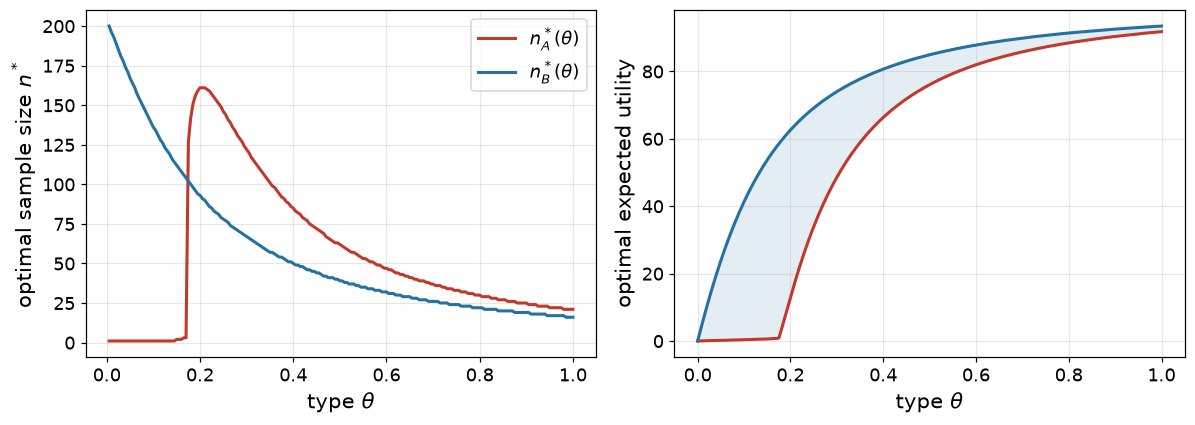

In [20]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.plot(thetas, nA, color=COL_A, label=r"$n_A^*(\theta)$")
ax.plot(thetas, nB, color=COL_B, label=r"$n_B^*(\theta)$")
# Added fontsize to labels and tick parameters
ax.set_xlabel(r"type $\theta$", fontsize=14)
ax.set_ylabel(r"optimal sample size $n^*$", fontsize=14)
ax.tick_params(axis='both', labelsize=12)
ax.legend(fontsize=12)

ax = axes[1]
ax.plot(thetas, VA, color=COL_A, label=r"$V_A(\theta)$")
ax.plot(thetas, VB, color=COL_B, label=r"$V_B(\theta)$")
ax.fill_between(thetas, VA, VB, where=VB > VA, color=COL_B, alpha=0.12)
# Added fontsize to labels and tick parameters
ax.set_xlabel(r"type $\theta$", fontsize=14)
ax.set_ylabel("optimal expected utility", fontsize=14)
ax.tick_params(axis='both', labelsize=12)

plt.tight_layout()
plt.show()



## Figure 2 — headline: passing probability at the agent's optimal sample size

We are plotting $p_A(n_A^*(\theta), \theta)$ vs $p_B(n_B^*(\theta), \theta)$.

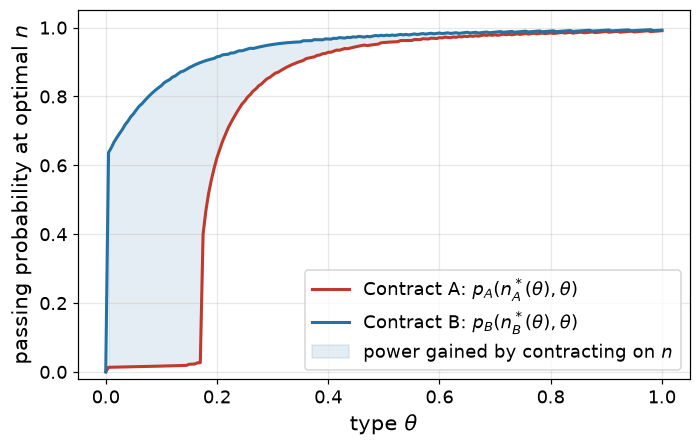

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(thetas, pA, color=COL_A, label=r"Contract A: $p_A(n_A^*(\theta),\theta)$")
ax.plot(thetas, pB, color=COL_B, label=r"Contract B: $p_B(n_B^*(\theta),\theta)$")
ax.fill_between(thetas, pA, pB, where=pB > pA, color=COL_B, alpha=0.12,
                label="power gained by contracting on $n$")

# 1. Add fontsize=14 to axis labels
ax.set_xlabel(r"type $\theta$", fontsize=14) 
ax.set_ylabel("passing probability at optimal $n$", fontsize=14)

# 2. Increase the size of the tick numbers 
ax.tick_params(axis='both', labelsize=12)

ax.set_ylim(-0.02, 1.05)
ax.legend(loc="lower right", fontsize=12)
plt.tight_layout()
plt.show()